# In silico model of the two-chamber device

Network model of the device: two hexagonal chambers connected by funnel-shaped
microchannels, axonal growth with collisions against the walls, and Izhikevich dynamics.

| Article figure | Section |
|---|---|
| Fig. 3a – geometry of the chip | 4 |
| Fig. 3b – seeding of the somas | 6 |
| Fig. 3d – axonal growth and final network | 6 |
| Fig. 3e – spontaneous activity, 600 s | 7 |
| Fig. 5h – connections between chambers and $\mathrm{DI}_{\mathrm{struct}}$, 10 networks | 8 |
| Fig. 5i – response to stimulation, example network | 9 |
| Fig. 5j – response of the opposite chamber, 10 networks | 9 |

Every figure is saved in `figures/` as vector PDF and 300 dpi PNG. The values of every
network (connections, $\mathrm{DI}_{\mathrm{struct}}$, responses to stimulation) are saved in
`in_silico_networks.csv`.

Fig. 3c is a schematic drawing. The 10 networks (seeds 0–9) are built once (section 5) and
used for Figs. 5h and 5j; the example network of Figs. 3b, 3d, 3e and 5i is one of them
(`EXAMPLE_SEED`).

Requirements: numpy, scipy, pandas, matplotlib. Running the whole notebook takes about 10 minutes.

## 1. Libraries

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import os
import pandas as pd
from scipy.stats import ttest_rel

SOURCE_COLOR, TARGET_COLOR = '#1f77b4', '#d62728'
ms_to_s = FuncFormatter(lambda x, pos: f'{x/1000:g}')

FIGURES = 'figures'
os.makedirs(FIGURES, exist_ok=True)

def save(fig, name):
    # Saves a figure as vector PDF and as 300 dpi PNG in the figures folder
    fig.savefig(os.path.join(FIGURES, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(FIGURES, f'{name}.png'), dpi=300, bbox_inches='tight')

## 2. Parameters

In [29]:
# ---------------------------------------------------------------------------
# Geometry of the chip (mm)
# ---------------------------------------------------------------------------
R_well = 3.68                    # circumradius of each hexagonal chamber (centre to vertex)
r_apothem = R_well*np.sqrt(3)/2  # centre to the middle of a flat side

L_channel = 0.5                  # length of the microchannels = thickness of the central wall
w_in = 0.03                      # channel width at the source side (wide end of the funnel)
w_out = 0.003                    # channel width at the target side (narrow end)
channel_pitch = 0.05             # distance between the centres of two consecutive channels
margin = 0.1                     # wall left free above and below the channel array

usable_height = R_well - 2*margin
n_channels = int(usable_height/channel_pitch) + 1
y_span = (n_channels - 1)*channel_pitch
channel_y_centers = np.linspace(-y_span/2, y_span/2, n_channels)

# Source chamber (A) on the left, target chamber (B) on the right; channels between x = 0 and x = L_channel
cx_A = -r_apothem
cx_B = L_channel + r_apothem

X_MIN, X_MAX = cx_A - r_apothem, cx_B + r_apothem
Y_MIN, Y_MAX = -R_well, R_well

# ---------------------------------------------------------------------------
# Neurons
# ---------------------------------------------------------------------------
rho = 15                                  # neuronal density (neurons/mm^2)
area_hex = 1.5*np.sqrt(3)*R_well**2       # area of one chamber
N_per_well = int(rho*area_hex)
N = 2*N_per_well

r_dend_mean = 0.075       # mean radius of the dendritic field (mm), i.e. 0.15 mm diameter
r_dend_sigma = 0.01       # standard deviation of the dendritic radius (mm)

# ---------------------------------------------------------------------------
# Seeding of the somas
# ---------------------------------------------------------------------------
n_centers = 10            # aggregation centres per chamber
base_sigma = 0.15         # typical spread of an aggregate (mm)
topo_sigma = 0.3          # spread of the somas along x away from the channels (ladders)
min_center_dist = 0.6     # minimum distance between aggregation centres (mm)
ladder_dist = 1.1         # distance from the channels to the ladder step (only drawn)

# ---------------------------------------------------------------------------
# Axonal growth and connectivity
# ---------------------------------------------------------------------------
l_mean = 1.5              # scale of the Rayleigh distribution of axon lengths (mm)
segment_length = 0.02     # length of each growth step (mm)
sigma_axon_angle = 0.15   # standard deviation of the change of direction per step (rad)
p_connection = 0.1        # probability that an axon entering a dendritic field forms a synapse

# ---------------------------------------------------------------------------
# Izhikevich dynamics
# ---------------------------------------------------------------------------
MAX_EXC_WEIGHT = 35.0     # maximum excitatory synaptic weight
MAX_INH_WEIGHT = 80.0     # maximum inhibitory synaptic weight
NOISE_EXC = 1.9             # amplitude of the background noise, excitatory neurons
NOISE_INH = 0.3           # amplitude of the background noise, inhibitory neurons
SIM_TIME = 600000         # duration of the spontaneous activity (ms) = 600 s, as the recordings

# Stimulation (Figs. 5i, 5j)
T_STIM_S, T_STIM_T = 1500, 2000   # stimulation times of the source and the target (ms)
STIM_AMPLITUDE = 60.0             # current injected in every neuron of the stimulated chamber
RESPONSE_WINDOW = 500             # response window after each stimulus (ms)

# Networks
N_NETWORKS = 10           # independent networks (seeds 0 to 9), Figs. 5h and 5j
EXAMPLE_SEED = 2          # network shown in Figs. 3b, 3d, 3e and 5i

## 3. Functions

### Geometry of the chip

In [30]:
def get_hex_vertices(cx, cy, R):
    """Vertices of a hexagon with flat left/right sides, centre (cx, cy) and circumradius R."""
    r_apo = R*np.sqrt(3)/2
    return [(cx, cy + R), (cx + r_apo, cy + R/2), (cx + r_apo, cy - R/2),
            (cx, cy - R), (cx - r_apo, cy - R/2), (cx - r_apo, cy + R/2)]


def is_inside_hex(x, y, cx, cy, R):
    """True if the point (x, y) is inside the hexagon of centre (cx, cy) and circumradius R."""
    dx, dy = abs(x - cx), abs(y - cy)
    if dx > R*np.sqrt(3)/2:          # beyond a flat side
        return False
    if dy > R - dx/np.sqrt(3):       # beyond a diagonal side
        return False
    return True


def is_inside_chip(x, y):
    """True if (x, y) is free space (a chamber or a microchannel), False if it is PDMS wall."""
    if is_inside_hex(x, y, cx_A, 0, R_well) or is_inside_hex(x, y, cx_B, 0, R_well):
        return True
    if 0 < x < L_channel:
        width = w_in - (x/L_channel)*(w_in - w_out)     # funnel: width decreases linearly with x
        for cy in channel_y_centers:
            if cy - width/2 <= y <= cy + width/2:
                return True
    return False


def draw_chip(ax, ladders=True):
    """Walls of the chip: the two chambers, the microchannels and (optionally) the ladder steps."""
    for cx in (cx_A, cx_B):
        ax.add_patch(Polygon(get_hex_vertices(cx, 0, R_well), fill=False, color='black', lw=2, zorder=10))
    for cy in channel_y_centers:
        ax.plot([0, L_channel], [cy + w_in/2, cy + w_out/2], color='black', lw=1, zorder=10)
        ax.plot([0, L_channel], [cy - w_in/2, cy - w_out/2], color='black', lw=1, zorder=10)
    if ladders:
        for x, cx, label in ((-ladder_dist, cx_A, 'Ladders'), (L_channel + ladder_dist, cx_B, None)):
            y_max = R_well - abs(x - cx)/np.sqrt(3)
            ax.plot([x, x], [-y_max, y_max], color='black', ls='--', lw=1, alpha=0.6, zorder=10, label=label)

### Network construction: somas, axonal growth and synapses

In [31]:
def seed_somas():
    """
    Positions of the somas: N_per_well neurons in each chamber, grouped in aggregates.
    The aggregation centres are drawn closer to the channels (ladders of the device):
    their distance to the channels along x is |Normal(0, topo_sigma)|.
    """
    def fill_chamber(cx, is_source):
        def random_point():
            dx = np.abs(np.random.normal(0, topo_sigma))
            x = -dx if is_source else L_channel + dx
            return x, np.random.uniform(-R_well, R_well)

        # Aggregation centres, at least min_center_dist apart
        centers, attempts = [], 0
        while len(centers) < n_centers and attempts < 5000:
            attempts += 1
            x, y = random_point()
            if is_inside_hex(x, y, cx, 0, R_well):
                if not centers or np.all(np.linalg.norm(np.array(centers) - [x, y], axis=1) >= min_center_dist):
                    centers.append([x, y])
                    attempts = 0
        n_c = len(centers)
        spreads = np.random.uniform(0.2*base_sigma, 1.5*base_sigma, n_c)   # each aggregate has its own spread
        weights = np.random.rand(n_c)
        weights = weights/weights.sum()                                     # and its own share of neurons

        # Somas around the centres (Gaussian), kept only if inside the chamber
        points = []
        while len(points) < N_per_well:
            k = np.random.choice(n_c, p=weights)
            x = np.random.normal(centers[k][0], spreads[k])
            y = np.random.normal(centers[k][1], spreads[k])
            if is_inside_hex(x, y, cx, 0, R_well):
                points.append([x, y])
        return np.array(points)

    return np.vstack((fill_chamber(cx_A, True), fill_chamber(cx_B, False)))


def growth_step(pos, angle, max_attempts=15):
    """
    One growth step of an axon tip. If the step hits a wall, new directions are tried,
    alternating left and right with increasing angle (Fig. 3c).
    Inside a channel and moving towards the target, the funnel walls keep the axon
    straight (small angle changes); in the chambers, or moving back towards the source,
    larger turns are allowed.
    """
    in_channel = 0 <= pos[0] <= L_channel
    a = (angle + np.pi) % (2*np.pi) - np.pi
    towards_source = a > np.pi/2 or a < -np.pi/2
    guided = in_channel and not towards_source

    for attempt in range(max_attempts):
        shift = 0 if attempt == 0 else attempt*(0.05 if guided else 0.2)*(1 if attempt % 2 == 0 else -1)
        test_angle = angle + shift
        step = np.array([np.cos(test_angle), np.sin(test_angle)])
        # The whole step must be in free space (checked at 20%, 40%, ..., 100% of its length)
        if all(is_inside_chip(*(pos + segment_length*f*step)) for f in np.linspace(0.2, 1.0, 5)):
            return pos + segment_length*step, test_angle

    # No free direction: a guided axon stops; otherwise it turns back
    return (pos, angle) if guided else (pos, angle + np.pi)


def grow_axon(i, positions, dendritic_radii):
    """
    Grows the axon of neuron i as a random walk and returns its segments and the
    neurons it connects to. When the tip enters the dendritic field of another neuron
    for the first time, a synapse is formed with probability p_connection.
    """
    n_steps = int(np.ceil(np.random.rayleigh(l_mean)/segment_length))
    angle = np.random.uniform(0, 2*np.pi)
    pos = np.array(positions[i], dtype=float)
    segments, targets, contacted = [], [], set()

    for step in range(n_steps):
        new_pos, angle = growth_step(pos, angle)
        if step % 2 == 0:            # contacts checked every second step (40 µm)
            inside = np.where(np.linalg.norm(positions - new_pos, axis=1) < dendritic_radii)[0]
            for j in inside:
                if j != i and j not in contacted:
                    contacted.add(j)
                    if np.random.rand() < p_connection:
                        targets.append(j)
        if not np.array_equal(pos, new_pos):
            segments.append((tuple(pos), tuple(new_pos)))
            pos = new_pos
        angle += np.random.normal(0, sigma_axon_angle)
    return segments, targets


def build_network(seed):
    """
    Builds one network: somas, dendritic radii and axons.
    Returns the soma positions, the adjacency matrix W (W[i, j] = 1 if neuron i
    connects to neuron j) and the axon segments of every neuron.
    """
    np.random.seed(seed)
    positions = seed_somas()
    dendritic_radii = np.random.normal(r_dend_mean, r_dend_sigma, N)
    W = np.zeros((N, N))
    axons = []
    for i in range(N):
        segments, targets = grow_axon(i, positions, dendritic_radii)
        W[i, targets] = 1
        axons.append(segments)
    return positions, W, axons


def chamber_of(positions):
    """Indices of the neurons of the source (left) and target (right) chambers."""
    source = np.where(positions[:, 0] < L_channel/2)[0]
    target = np.where(positions[:, 0] >= L_channel/2)[0]
    return source, target

### Izhikevich dynamics

In [32]:
def setup_izhikevich(W):
    """
    Izhikevich neurons on the network W: 80% excitatory (regular spiking) and 20%
    inhibitory (fast spiking), assigned at random. Synaptic weights are uniform in
    [0, MAX_EXC_WEIGHT] for excitatory and [-MAX_INH_WEIGHT, 0] for inhibitory neurons.
    """
    types = np.array(['E']*int(0.8*N) + ['I']*(N - int(0.8*N)))
    np.random.shuffle(types)
    is_exc = types == 'E'
    is_inh = ~is_exc
    Ne, Ni = int(is_exc.sum()), int(is_inh.sum())
    re, ri = np.random.rand(Ne), np.random.rand(Ni)

    a, b, c, d = np.zeros(N), np.zeros(N), np.zeros(N), np.zeros(N)
    a[is_exc], b[is_exc] = 0.02, 0.2
    c[is_exc], d[is_exc] = -65 + 15*re**2, 8 - 6*re**2
    a[is_inh], b[is_inh] = 0.02 + 0.08*ri, 0.25 - 0.05*ri
    c[is_inh], d[is_inh] = -65, 2

    S = np.zeros((N, N))           # S[i, j]: weight of the synapse from i to j
    for i in range(N):
        if is_exc[i]:
            S[i, :] = W[i, :]*(MAX_EXC_WEIGHT*np.random.rand(N))
        else:
            S[i, :] = W[i, :]*(-MAX_INH_WEIGHT*np.random.rand(N))
    return dict(is_exc=is_exc, is_inh=is_inh, Ne=Ne, Ni=Ni, a=a, b=b, c=c, d=d, S=S)


def run_dynamics(par, sim_time, noise_exc=NOISE_EXC, noise_inh=NOISE_INH, stim=None):
    """
    Simulates the network for sim_time ms (time step 1 ms, membrane potential
    integrated in two half steps). stim = {t: [(neuron indices, amplitude), ...]}
    injects a current at time t. Returns the time (ms) and neuron of every spike.
    """
    is_exc, is_inh, S = par['is_exc'], par['is_inh'], par['S']
    a, b, c, d = par['a'], par['b'], par['c'], par['d']
    v = -65*np.ones(N)
    u = b*v
    spike_t, spike_n = [], []

    for t in range(sim_time):
        I = np.zeros(N)
        I[is_exc] = noise_exc*np.random.randn(par['Ne'])
        I[is_inh] = noise_inh*np.random.randn(par['Ni'])
        if stim is not None and t in stim:
            for idx, amp in stim[t]:
                I[idx] += amp

        fired = np.where(v >= 30)[0]
        if len(fired):
            spike_t.extend([t]*len(fired))
            spike_n.extend(fired.tolist())
            I += S[fired, :].sum(axis=0)
        v[fired] = c[fired]
        u[fired] = u[fired] + d[fired]

        v = v + 0.5*(0.04*v**2 + 5*v + 140 - u + I)
        v = v + 0.5*(0.04*v**2 + 5*v + 140 - u + I)
        u = u + a*(b*v - u)
    return np.array(spike_t), np.array(spike_n)

## 4. Geometry of the chip (Fig. 3a)

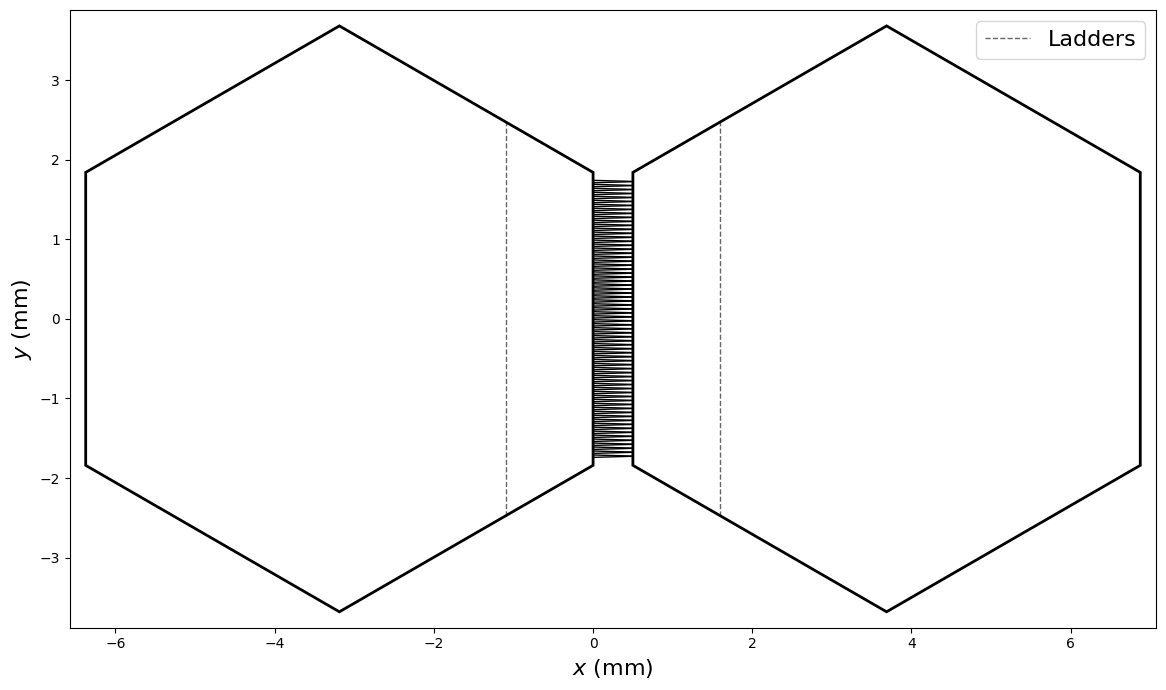

Circumradius 3.68 mm, 70 channels, 527 neurons per chamber (N = 1054)


In [33]:
fig, ax = plt.subplots(figsize=(13, 7))
draw_chip(ax)
ax.set_aspect('equal')
ax.set_xlim(X_MIN - 0.2, X_MAX + 0.2)
ax.set_ylim(Y_MIN - 0.2, Y_MAX + 0.2)
ax.set_xlabel('$x$ (mm)', fontsize=16)
ax.set_ylabel('$y$ (mm)', fontsize=16)
ax.legend(loc='upper right', fontsize=16)
plt.tight_layout()
save(fig, 'fig3a')
plt.show()
print(f'Circumradius {R_well} mm, {n_channels} channels, {N_per_well} neurons per chamber (N = {N})')

## 5. The 10 networks

Each network is built from its own seed (0 to 9). The Izhikevich parameters of each
network are drawn right after it is built, so every network and its dynamics are reproducible.

In [34]:
networks = []
for seed in range(N_NETWORKS):
    positions, W, axons = build_network(seed)
    par = setup_izhikevich(W)
    networks.append(dict(positions=positions, W=W, axons=axons, par=par))
    print(f'network {seed}: {int(W.sum())} connections')

network 0: 4005 connections
network 1: 4358 connections
network 2: 3355 connections
network 3: 3248 connections
network 4: 4383 connections
network 5: 3256 connections
network 6: 4105 connections
network 7: 3605 connections
network 8: 4344 connections
network 9: 4437 connections


## 6. Example network: somas (Fig. 3b) and final network (Fig. 3d)

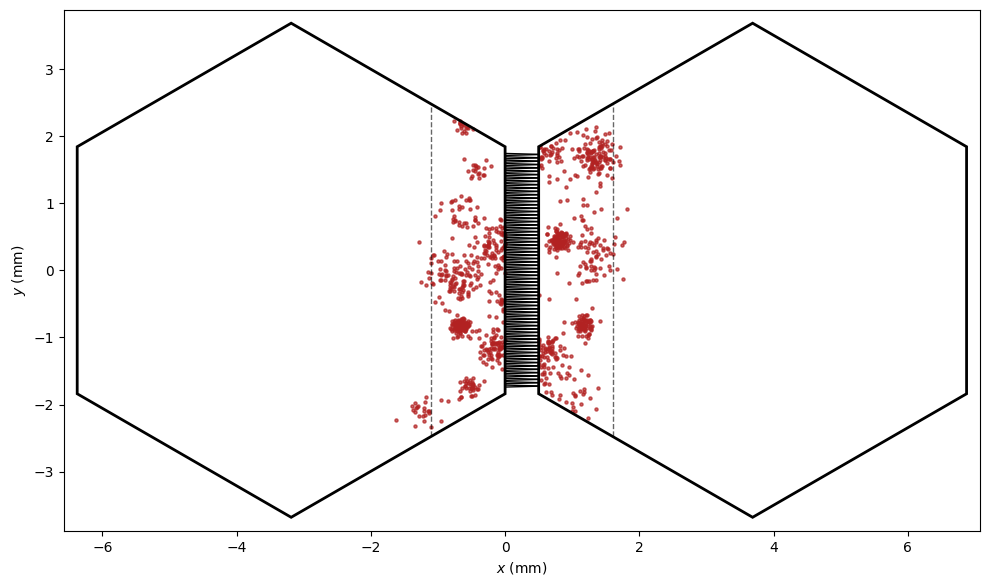

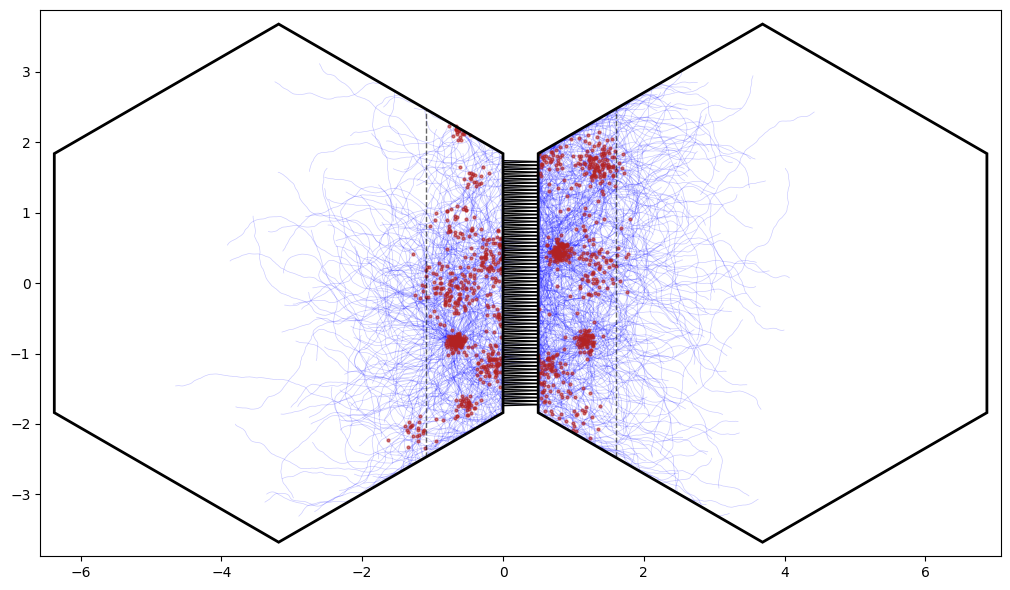

In [35]:
example = networks[EXAMPLE_SEED]
positions = example['positions']

# Fig. 3b: somas
fig, ax = plt.subplots(figsize=(10, 6))
draw_chip(ax)
ax.scatter(positions[:, 0], positions[:, 1], s=5, color='firebrick', alpha=0.7, zorder=5)
ax.set_aspect('equal')
ax.set_xlim(X_MIN - 0.2, X_MAX + 0.2)
ax.set_ylim(Y_MIN - 0.2, Y_MAX + 0.2)
ax.set_xlabel('$x$ (mm)')
ax.set_ylabel('$y$ (mm)')
plt.tight_layout()
save(fig, 'fig3b')
plt.show()

# Fig. 3d: axons and somas
fig, ax = plt.subplots(figsize=(12, 6))
draw_chip(ax)
segments = [seg for axon in example['axons'] for seg in axon]
ax.add_collection(LineCollection(segments, colors='blue', linewidths=0.5, alpha=0.2, zorder=2, rasterized=True))
ax.scatter(positions[:, 0], positions[:, 1], s=4, c='firebrick', alpha=0.6, zorder=5)
ax.set_aspect('equal')
ax.set_xlim(X_MIN - 0.2, X_MAX + 0.2)
ax.set_ylim(Y_MIN - 0.2, Y_MAX + 0.2)
plt.tight_layout()
save(fig, 'fig3d')
plt.show()

## 7. Spontaneous activity of the example network (Fig. 3e)

600 s of activity driven by background noise, the same duration as the experimental recordings.

6831 spikes, 631 of 1054 neurons active, 0.01 spikes/s per neuron


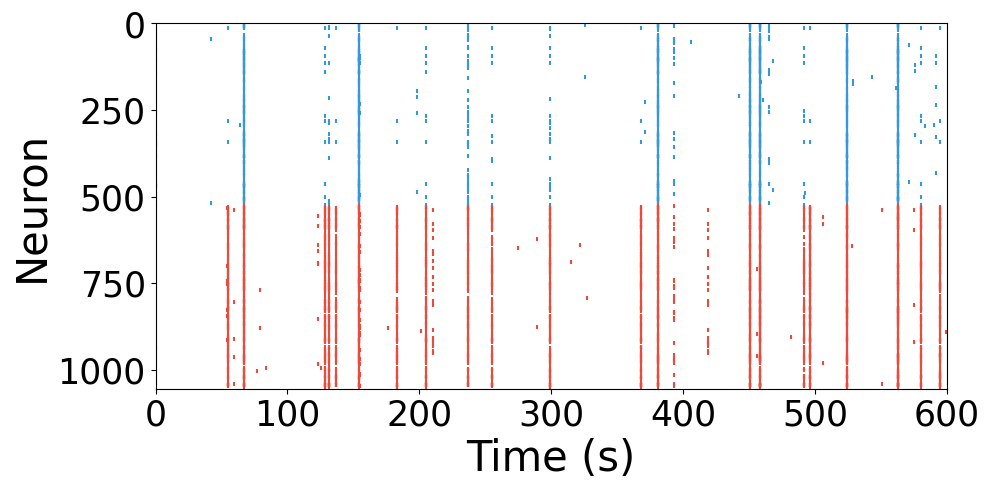

In [45]:
np.random.seed(EXAMPLE_SEED)
spike_t, spike_n = run_dynamics(example['par'], sim_time=SIM_TIME)
source, target = chamber_of(positions)
print(f'{len(spike_t)} spikes, {len(np.unique(spike_n))} of {N} neurons active, '
      f'{len(spike_t)/N/(SIM_TIME/1000):.2f} spikes/s per neuron')

in_source = np.isin(spike_n, source)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(spike_t[in_source], spike_n[in_source], s=5, c='#3498db', marker='|', alpha=1, rasterized=True)
ax.scatter(spike_t[~in_source], spike_n[~in_source], s=5, c='#e74c3c', marker='|', alpha=1, rasterized=True)
ax.xaxis.set_major_formatter(ms_to_s)
ax.set_xlim(0, SIM_TIME)
ax.set_ylim(N, 0)
ax.set_xlabel('Time (s)', fontsize=30)
ax.set_ylabel('Neuron', fontsize=30)
ax.tick_params(labelsize=25)
plt.tight_layout()
save(fig, 'fig3e')
plt.show()

## 8. Structural directionality over the 10 networks (Fig. 5h)

Connections are classified by the chambers they link: within the source (S→S), within the
target (T→T), source to target (S→T) and target to source (T→S).
$\mathrm{DI}_{\mathrm{struct}} = (n_{S\to T} - n_{T\to S}) / (n_{S\to T} + n_{T\to S})$.
Mean ± SEM over the 10 networks.

S→S: 1757 ± 135
T→T: 1947 ± 90
S→T: 196 ± 12
T→S: 10 ± 2
DI_struct = 0.90 ± 0.02  (mean ± SEM, n = 10 networks)


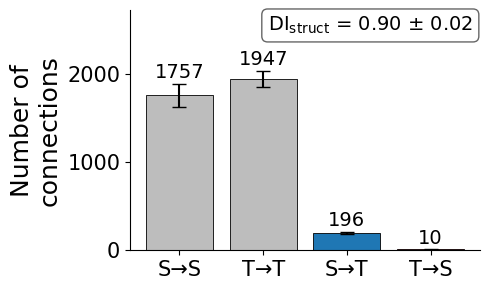

In [37]:
def mean_sem(x):
    x = np.asarray(x, float)
    return x.mean(), x.std(ddof=1)/np.sqrt(len(x))

counts = {'S→S': [], 'T→T': [], 'S→T': [], 'T→S': []}
DI_struct = []
for net in networks:
    x = net['positions'][:, 0]
    pre, post = np.where(net['W'] > 0)
    in_S_pre, in_S_post = x[pre] < 0, x[post] < 0                    # source chamber: x < 0
    in_T_pre, in_T_post = x[pre] > L_channel, x[post] > L_channel    # target chamber: x > L_channel
    counts['S→S'].append(np.sum(in_S_pre & in_S_post))
    counts['T→T'].append(np.sum(in_T_pre & in_T_post))
    counts['S→T'].append(np.sum(in_S_pre & in_T_post))
    counts['T→S'].append(np.sum(in_T_pre & in_S_post))
    st, ts = counts['S→T'][-1], counts['T→S'][-1]
    DI_struct.append((st - ts)/(st + ts))

stats = {k: mean_sem(v) for k, v in counts.items()}
di_mean, di_sem = mean_sem(DI_struct)
for k, (m, s) in stats.items():
    print(f'{k}: {m:.0f} ± {s:.0f}')
print(f'DI_struct = {di_mean:.2f} ± {di_sem:.2f}  (mean ± SEM, n = {N_NETWORKS} networks)')

fig, ax = plt.subplots(figsize=(5, 3))
labels = list(stats)
means = [stats[k][0] for k in labels]
sems = [stats[k][1] for k in labels]
bars = ax.bar(labels, means, yerr=sems, capsize=5, edgecolor='black', linewidth=0.6,
              color=['#bdbdbd', '#bdbdbd', SOURCE_COLOR, TARGET_COLOR])
top = max(means)
for bar, m, s in zip(bars, means, sems):
    ax.text(bar.get_x() + bar.get_width()/2, m + s + 0.01*top, f'{m:.0f}', ha='center', va='bottom', fontsize=14)
ax.text(0.98, 0.98, f'$\\mathrm{{DI}}_{{\\mathrm{{struct}}}}$ = {di_mean:.2f} ± {di_sem:.2f}',
        transform=ax.transAxes, ha='right', va='top', fontsize=14,
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.4'))
ax.set_ylabel('Number of\nconnections', fontsize=18)
ax.set_ylim(0, 1.4*top)
ax.tick_params(labelsize=15)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save(fig, 'fig5h')
plt.show()

## 9. Response to stimulation (Figs. 5i and 5j)

Without noise, all neurons of the source chamber are stimulated at t = 1.5 s and all
neurons of the target chamber at t = 2 s. The response is the percentage of neurons of the
opposite chamber that fire within 500 ms after the stimulus. Fig. 5i shows the example
network; Fig. 5j shows the 10 networks, compared with a paired t-test.

In [38]:
resp_S, resp_T, evoked = [], [], []
for net in networks:
    source, target = chamber_of(net['positions'])
    stim = {T_STIM_S: [(source, STIM_AMPLITUDE)], T_STIM_T: [(target, STIM_AMPLITUDE)]}
    t, n = run_dynamics(net['par'], sim_time=T_STIM_T + RESPONSE_WINDOW + 1,
                        noise_exc=0, noise_inh=0, stim=stim)
    evoked.append((t, n))
    after = lambda t0: (t >= t0) & (t < t0 + RESPONSE_WINDOW)
    resp_S.append(100*len(np.unique(n[after(T_STIM_S) & np.isin(n, target)]))/len(target))
    resp_T.append(100*len(np.unique(n[after(T_STIM_T) & np.isin(n, source)]))/len(source))
resp_S, resp_T = np.array(resp_S), np.array(resp_T)

t_stat, p_value = ttest_rel(resp_S, resp_T)
print(f'Stim. S -> target responds: {resp_S.mean():.1f} ± {resp_S.std(ddof=1)/np.sqrt(N_NETWORKS):.1f} %')
print(f'Stim. T -> source responds: {resp_T.mean():.1f} ± {resp_T.std(ddof=1)/np.sqrt(N_NETWORKS):.1f} %  (mean ± SEM)')
print(f'Paired t-test: t({N_NETWORKS - 1}) = {t_stat:.2f}, p = {p_value:.1e}')

# Values of every network (Figs. 5h and 5j)
results = pd.DataFrame({'seed': range(N_NETWORKS), 'S_to_S': counts['S→S'], 'T_to_T': counts['T→T'],
                        'S_to_T': counts['S→T'], 'T_to_S': counts['T→S'], 'DI_struct': DI_struct,
                        'response_stim_S_%': resp_S, 'response_stim_T_%': resp_T})
results.round(3).to_csv('in_silico_networks.csv', index=False)
results.round(2)

Stim. S -> target responds: 70.2 ± 2.5 %
Stim. T -> source responds: 24.0 ± 9.3 %  (mean ± SEM)
Paired t-test: t(9) = 5.03, p = 7.1e-04


,seed,S_to_S,T_to_T,S_to_T,T_to_S,DI_struct,response_stim_S_%,response_stim_T_%
0,0,1532,2250,201,22,0.80,76.09,37.38
1,1,2395,1779,179,5,0.95,70.78,62.24
2,2,1563,1512,275,5,0.96,51.04,1.90
3,3,1270,1812,157,9,0.89,63.57,0.38
4,4,2452,1724,194,13,0.87,70.02,69.07
5,5,1406,1700,144,6,0.92,72.30,2.28
6,6,1543,2358,187,17,0.83,78.37,0.38
7,7,1401,1971,222,11,0.91,73.24,7.02
8,8,1990,2123,231,0,1.00,74.00,0.00
9,9,2015,2240,173,9,0.90,72.87,59.01


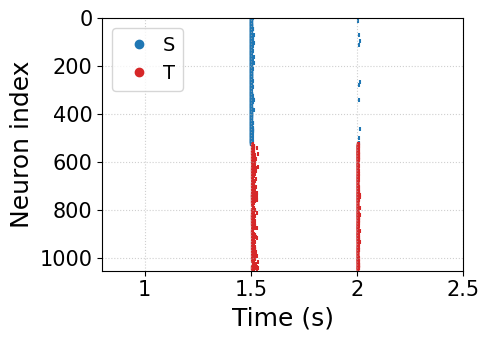

In [39]:
# Fig. 5i: example network
t, n = evoked[EXAMPLE_SEED]
source, target = chamber_of(networks[EXAMPLE_SEED]['positions'])
in_source = np.isin(n, source)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(t[in_source], n[in_source], s=5, c=SOURCE_COLOR, marker='|')
ax.scatter(t[~in_source], n[~in_source], s=5, c=TARGET_COLOR, marker='|')
ax.xaxis.set_major_formatter(ms_to_s)
ax.set_xticks([1000, 1500, 2000, 2500])
ax.set_xlim(800, 2500)
ax.set_ylim(N, 0)
ax.set_xlabel('Time (s)', fontsize=18)
ax.set_ylabel('Neuron index', fontsize=18)
ax.tick_params(labelsize=15)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=SOURCE_COLOR, label='S'),
                   Line2D([], [], marker='o', ls='', color=TARGET_COLOR, label='T')],
          loc='upper left', fontsize=14, handletextpad=0.2)
plt.tight_layout()
save(fig, 'fig5i')
plt.show()

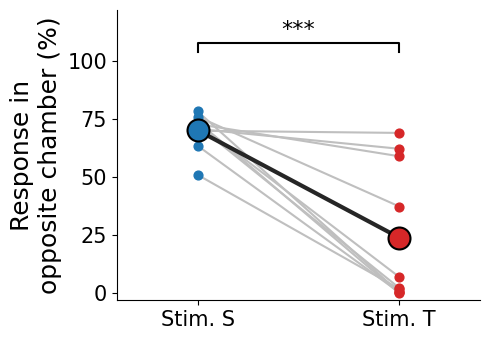

In [40]:
# Fig. 5j: 10 networks
stars = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'n.s.'
fig, ax = plt.subplots(figsize=(5, 3.5))
for a, b in zip(resp_S, resp_T):
    ax.plot([0, 1], [a, b], color='0.75', lw=1.5, zorder=1)
ax.scatter(np.zeros(N_NETWORKS), resp_S, color=SOURCE_COLOR, s=40, zorder=2)
ax.scatter(np.ones(N_NETWORKS), resp_T, color=TARGET_COLOR, s=40, zorder=2)
ax.plot([0, 1], [resp_S.mean(), resp_T.mean()], color='0.15', lw=3, zorder=3)
ax.scatter([0], [resp_S.mean()], color=SOURCE_COLOR, s=250, edgecolor='black', lw=1.5, zorder=4)
ax.scatter([1], [resp_T.mean()], color=TARGET_COLOR, s=250, edgecolor='black', lw=1.5, zorder=4)
ax.plot([0, 0, 1, 1], [104, 108, 108, 104], color='black', lw=1.5)
ax.text(0.5, 109, stars, ha='center', va='bottom', fontsize=16)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Stim. S', 'Stim. T'])
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xlim(-0.4, 1.4)
ax.set_ylim(-3, 122)
ax.set_ylabel('Response in\nopposite chamber (%)', fontsize=18)
ax.tick_params(labelsize=15)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save(fig, 'fig5j')
plt.show()